# Lecture 4: Quantitative Validity of the Real Business Cycle Model

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/johanneswieland/RBC/blob/main/lectures/04_quantitative_validity.ipynb)

**Economics 210A: Real Business Cycles** · Johannes Wieland

We are now ready to assess the empirical success of the model we developed in Lectures 2 and 3. We evaluate it along several dimensions. Specifically, we look at the following properties of the data and check whether the model can reproduce them:

- volatility,
- correlations,
- amplification of shocks,
- propagation of shocks:
  - internal dynamics,
  - built-in persistence (serial correlation of the exogenous forcing variables).

We begin with the case for the model (Section 1) and then turn to its weaknesses. Ideally, we would like a model that does not rely heavily on the persistence and volatility of the exogenous forcing variables. Instead, we want a model that generates persistence and volatility **endogenously**.

## Readings

- King, R. G. and S. T. Rebelo (1999), "[Resuscitating Real Business Cycles](https://doi.org/10.1016/S1574-0048%2899%2910022-3)," *Handbook of Macroeconomics*, Vol. 1B, Ch. 14.
- Rotemberg, J. J. and M. Woodford (1996), "[Real-Business-Cycle Models and the Forecastable Movements in Output, Hours, and Consumption](https://ideas.repec.org/a/aea/aecrev/v86y1996i1p71-89.html)," *American Economic Review* 86(1).
- Galí, J. (1999), "[Technology, Employment, and the Business Cycle: Do Technology Shocks Explain Aggregate Fluctuations?](https://doi.org/10.1257/aer.89.1.249)," *American Economic Review* 89(1).
- Basu, S., J. G. Fernald, and M. S. Kimball (2006), "[Are Technology Improvements Contractionary?](https://doi.org/10.1257/aer.96.5.1418)," *American Economic Review* 96(5).
- Chari, V. V., P. J. Kehoe, and E. R. McGrattan (2007), "[Business Cycle Accounting](https://doi.org/10.1111/j.1468-0262.2007.00768.x)," *Econometrica* 75(3).
- Shimer, R. (2009), "[Convergence in Macroeconomics: The Labor Wedge](https://doi.org/10.1257/mac.1.1.280)," *American Economic Journal: Macroeconomics* 1(1).

## Setup

The model code is in [`code/rbc_ct.py`](../code/rbc_ct.py), as in Lectures 2 and 3. The data come from [`code/bcdata.py`](../code/bcdata.py), as in Lecture 1.

In [1]:
import sys, os
if "google.colab" in sys.modules and not os.path.exists("RBC"):
    !git clone -q https://github.com/johanneswieland/RBC.git
    os.chdir("RBC/lectures")
sys.path.insert(0, os.path.abspath("../code"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rbc_ct as rbc
import bcdata
from bcdata import COLORS, set_plot_style

set_plot_style()
pd.set_option("display.precision", 2)

p = rbc.Params(sg=0.2)          # calibration of Lecture 3: Lecture 2 parameters plus G/Y = 0.2

## 1. The quantitative success of the RBC model

[King and Rebelo (1999)](https://doi.org/10.1016/S1574-0048%2899%2910022-3) make the case that the basic RBC model, despite its simplicity, accounts for a large part of postwar U.S. business cycles. They test how well the calibrated model matches the business cycle facts of Lecture 1: standard deviations, autocorrelations, and correlations with output.

We already calibrated the model in Lectures 2 and 3: log utility in consumption, a Frisch elasticity $\eta = 1$, $\alpha = 1/3$, $\rho = 0.04$ and $\delta = 0.08$ per year, $\bar G/\bar Y = 0.2$, and technology with quarterly persistence 0.95. King and Rebelo then feed the *actual* Solow residual into the model (i.e., they plug it into the policy functions from Lecture 2) and compare the simulated series with the data, quarter by quarter. We do the same with our model and our calibration.

The data are the same as of Lecture 1.

In [2]:
END = None                  # latest data, including COVID-19; try "2019-12-31" (pre-COVID)
raw = bcdata.load_raw()
levels = bcdata.build_series(raw.loc[:END])
cycles, _ = bcdata.hp_cycles(levels)
data = bcdata.bc_moments(cycles)
T = len(levels)
print(f"{T} quarters, {levels.index[0]:%Y}Q{levels.index[0].quarter} to {levels.index[-1]:%Y}Q{levels.index[-1].quarter}")

Downloaded data: 1947-01-01 to 2026-07-01
318 quarters, 1947Q2 to 2026Q3


**Technology.** We measure $\hat z_t$ by the Solow residual of Lecture 1 relative to a linear trend. (The trend is balanced growth, which our model abstracts from. The HP filter removes any linear trend, so the HP-filtered $\hat z_t$ is exactly the HP-filtered Solow residual.)

**Expectations.** Households expect technology to return to trend at rate $\theta$, with quarterly persistence $e^{-\theta/4} = 0.95$ as in Lecture 2. Each quarter they observe a new value of the Solow residual, revise their expectations, and re-optimize. Their decisions are therefore given by the policy function (POL) of Lecture 2, $\hat\lambda_t = \nu_{\lambda k}\hat k_t + \nu_{\lambda z}\hat z_t$, evaluated at the current capital stock and the current Solow residual.

**Capital.** Capital is the only state variable that is not taken from the data. It starts at its steady state and accumulates according to (POL), $\dot{\hat k}_t = \mu_s\hat k_t + \nu_{kz}\hat z_t$. If $\hat z_t$ is constant over the quarter $[t, t+h)$, with $h = 1/4$ year, the solution of this differential equation over the quarter is

$$
\begin{aligned}
\hat k_{t+h} &= e^{\mu_s h}\hat k_t + \int_0^h e^{\mu_s (h-u)}\,du\;\nu_{kz}\hat z_t \\
&= e^{\mu_s h}\hat k_t + \frac{e^{\mu_s h} - 1}{\mu_s}\,\nu_{kz}\hat z_t .
\end{aligned}
\tag{HIST}
$$

Given $(\hat k_t, \hat\lambda_t, \hat z_t)$ we recover all other variables as in Lecture 2. We HP-filter the model series exactly like the data and compute the same moments. There is no free parameter: the size of the shocks is the size of the measured Solow residual. The last column correlates the HP-filtered model series with its counterpart in the data, quarter by quarter.

In [3]:
# model variable -> name of the data series
NAMES = {"Y": "GDP", "C": "Consumption", "I": "Investment", "L": "Hours", "W": "Real Wage",
         "K": "Capital", "r (p.p.)": "Real Rate", "Z": "TFP"}
ROWS = ["GDP", "Consumption", "Investment", "Hours", "GDP per Hour", "Real Wage", "Capital", "Real Rate", "TFP"]


def hp_cycle_matrix(T, lam=1600):
    # the HP cycle is y - tau with tau = (I + lam D'D)^{-1} y (Lecture 1), a linear map of y
    D = np.diff(np.eye(T), 2, axis=0)
    return np.eye(T) - np.linalg.inv(np.eye(T) + lam * D.T @ D)


HPC = hp_cycle_matrix(T)

theta = -4 * np.log(0.95)                     # quarterly persistence 0.95, as in Lecture 2
pc = rbc.policy_coefficients(p, theta)        # coefficients of (POL)

# technology: the Solow residual relative to a linear trend
tfp = levels["TFP"].values
q = np.arange(T)
z = tfp - np.polyval(np.polyfit(q, tfp, 1), q)

# capital: start at the steady state and integrate (POL) quarter by quarter, (HIST)
h = 0.25                                      # one quarter, in years
e = np.exp(pc["mu_s"] * h)
k = np.zeros(T)
for n in range(T - 1):
    k[n + 1] = e * k[n] + pc["nu_kz"] * (e - 1) / pc["mu_s"] * z[n]
lam = pc["nu_lk"] * k + pc["nu_lz"] * z       # (POL)

hist = rbc.derived(p, levels.index, k, lam, z, np.zeros(T))
x = hist.rename(columns=NAMES)[list(NAMES.values())]
x["GDP per Hour"] = x["GDP"] - x["Hours"]
fed = pd.DataFrame(HPC @ x.values, index=levels.index, columns=x.columns)   # HP cycles, in %

kr = pd.concat({"Data": data.loc[ROWS], "Model: measured Solow residual": bcdata.bc_moments(fed).loc[ROWS]}, axis=1)
kr[("", "Corr(model, data)")] = fed[ROWS].corrwith(cycles[ROWS])
kr

Data                                             \
             SD (%) SD / SD(GDP) Corr(x, GDP) Corr(x_t, x_t-1)   
GDP            2.07         1.00         1.00             0.80   
Consumption    1.06         0.51         0.76             0.68   
Investment     6.30         3.05         0.88             0.80   
Hours          2.01         0.97         0.86             0.81   
GDP per Hour   1.07         0.51         0.32             0.75   
Real Wage      1.16         0.56         0.02             0.73   
Capital        0.54         0.26        -0.12             0.96   
Real Rate      1.77         0.85        -0.02             0.50   
TFP            1.20         0.58         0.78             0.77   

             Model: measured Solow residual                            \
                                     SD (%) SD / SD(GDP) Corr(x, GDP)   
GDP                                    1.54         1.00         1.00   
Consumption                            0.59         0.38         0.89   
Investment                             5.62         3.64         0.99   
Hours                                  0.53         0.34         0.97   
GDP per Hour                           1.04         0.68         0.99   
Real Wage                              1.04         0.68         0.99   
Capital                                0.45         0.29         0.03   
Real Rate                              0.19         0.12         0.96   
TFP                                    1.20         0.78         1.00   

                                                 
             Corr(x_t, x_t-1) Corr(model, data)  
GDP                      0.78              0.80  
Consumption              0.83              0.57  
Investment               0.77              0.76  
Hours                    0.78              0.25  
GDP per Hour             0.79              0.77  
Real Wage                0.79              0.35  
Capital                  0.96              0.37  
Real Rate                0.78             -0.12  
TFP                      0.77              1.00

The real rate is in percentage points; all other variables are in percent. The TFP row is the same in the model and the data by construction. Fed with nothing but the measured Solow residual, our model reproduces a lot:

1. It generates about three quarters of the volatility of output (1.5% vs. 2.1%).
2. It gets the ranking of volatilities right: investment is more than three times as volatile as output, and consumption is much less volatile than output (0.38 times as volatile, 0.51 in the data).
3. Output, consumption, and investment are about as persistent as in the data (consumption somewhat more), and they are procyclical.
4. The model series track the data quarter by quarter: the correlation between model and data output is 0.80, for investment 0.76, and for consumption 0.57.

The weak spot is the labor market. Hours in the model are only about a quarter as volatile as in the data, and the correlation between model and data hours is only about 0.25. The real wage is much too procyclical, and the real interest rate barely moves.

The figure plots the HP-filtered series, as in King and Rebelo's figures; grey bars are NBER recessions. The model reproduces the timing and depth of most postwar recessions in output, consumption, and investment, because the Solow residual falls in almost every recession (Lecture 1). Hours are a different story. In the model hours move with the Solow residual and have small amplitude. In the data hours fall by much more in recessions, and they keep falling after the recessions of 1990–91, 2001, and 2007–09 ("jobless recoveries"), while the Solow residual, and with it hours in the model, recovers quickly.

The big exception is the COVID-19 recession. In 2020Q2 output fell almost 12% below trend, but the Solow residual fell by less than 3%, so output in the model falls by less than 4%. Afterwards the Solow residual is above trend, and the model predicts a boom in 2020–21 while hours in the data recover slowly.

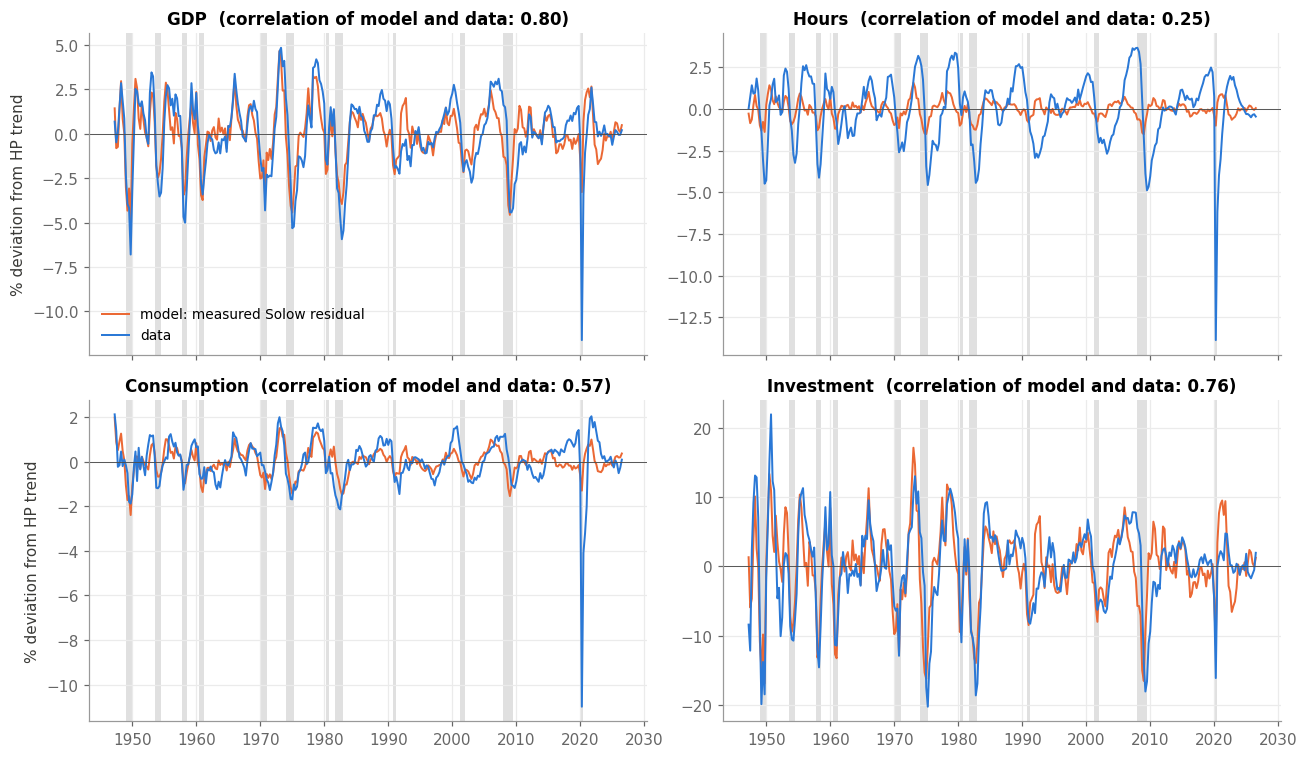

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
for ax, var in zip(axes.flat, ["GDP", "Hours", "Consumption", "Investment"]):
    bcdata.shade_recessions(ax, levels["recession"])
    ax.plot(fed.index, fed[var], color=COLORS["series"], lw=1.3, label="model: measured Solow residual")
    ax.plot(cycles.index, cycles[var], color=COLORS["gdp"], lw=1.3, label="data")
    ax.axhline(0, color="0.3", lw=0.6)
    ax.set_title(f"{var}  (correlation of model and data: {kr.loc[var, ('', 'Corr(model, data)')]:.2f})")
for ax in axes[:, 0]:
    ax.set_ylabel("% deviation from HP trend")
axes[0, 0].legend(loc="lower left", fontsize=9)
plt.tight_layout()

### 1.1 Conditional moments

We can also assess the model against the conditional impulse response functions that we estimated in Lecture 1. The model closely matches the IRFs for output, consumption, and investment. But like the unconditional moments, it is less successful in the labor market by overpredicting real wage movements and underpredicting hours changes.

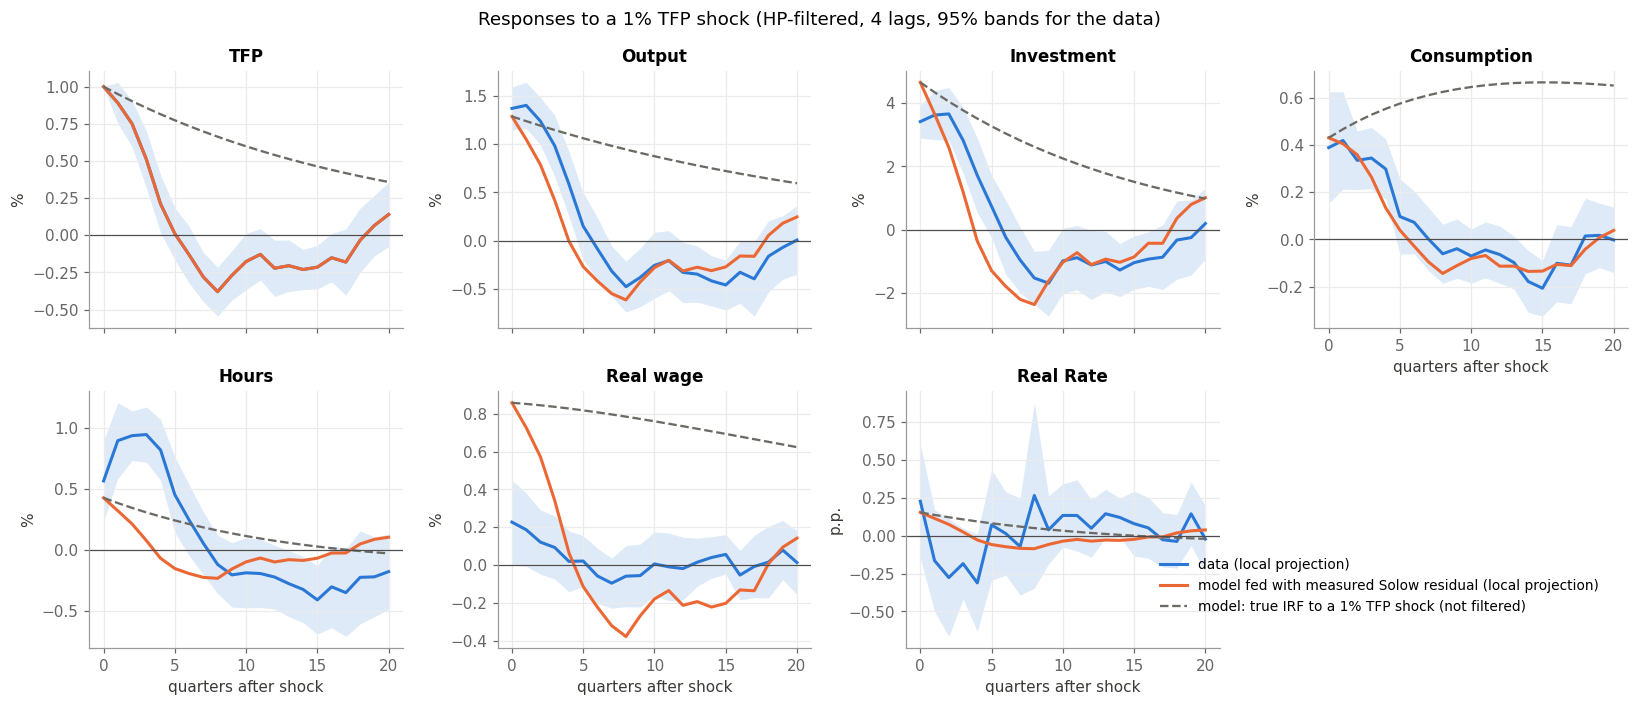

In [5]:
# conditional IRFs: local projections on the HP-filtered Solow residual, as in Lecture 1 (Section 5)
import statsmodels.api as sm
from scipy.stats import norm

H_LP, LAGS_LP, CONF = 20, 4, 0.95
lp_vars = ["TFP", "GDP", "Investment", "Consumption", "Hours", "Real Wage", "Real Rate"]


def local_projection(y, shock, H=20, lags=4, conf=0.95):
    # IRF of y to shock: for each h, regress y_{t+h} on shock_t, `lags` lags of shock and of y (Lecture 1)
    same = y.equals(shock)
    X = pd.concat({"shock": shock,
                   **{f"shock_l{j}": shock.shift(j) for j in range(1, lags + 1)},
                   **({} if same else {f"y_l{j}": y.shift(j) for j in range(1, lags + 1)})}, axis=1)
    X = sm.add_constant(X)
    zc = norm.ppf(0.5 + conf / 2)
    rows = []
    for hh in range(H + 1):
        d = pd.concat([y.shift(-hh).rename("lhs"), X], axis=1).dropna()
        res = sm.OLS(d["lhs"], d.drop(columns="lhs")).fit(cov_type="HAC", cov_kwds={"maxlags": hh + 1})
        b, se = res.params["shock"], res.bse["shock"]
        rows.append({"h": hh, "irf": b, "lo": b - zc * se, "hi": b + zc * se})
    return pd.DataFrame(rows).set_index("h")


lp_data = {v: local_projection(cycles[v], cycles["TFP"], H_LP, LAGS_LP, CONF) for v in lp_vars}
lp_model = {v: local_projection(fed[v], fed["TFP"], H_LP, LAGS_LP, CONF) for v in lp_vars}
true_irf = rbc.irf(p, z0=0.01, theta_z=theta, T=H_LP / 4, n=H_LP + 1).rename(columns=NAMES)   # 1% TFP shock

titles = {"GDP": "Output", "Real Wage": "Real wage"}
fig, axes = plt.subplots(2, 4, figsize=(15, 6.5), sharex=True)
hq = np.arange(H_LP + 1)
for ax, v in zip(axes.flat, lp_vars):
    r = lp_data[v]
    ax.fill_between(hq, r["lo"], r["hi"], color=COLORS["gdp"], alpha=0.15, lw=0)
    ax.plot(hq, r["irf"], color=COLORS["gdp"], lw=2, label="data (local projection)")
    ax.plot(hq, lp_model[v]["irf"], color=COLORS["series"], lw=2,
            label="model fed with measured Solow residual (local projection)")
    ax.plot(hq, true_irf[v].values, color=COLORS["trend"], lw=1.5, ls="--",
            label="model: true IRF to a 1% TFP shock (not filtered)")
    ax.axhline(0, color="0.3", lw=0.8)
    ax.set_title(titles.get(v, v))
    ax.set_ylabel("p.p." if v == "Real Rate" else "%")
axes[1, 3].remove()
axes[0, 3].tick_params(labelbottom=True)
for ax in [*axes[1, :3], axes[0, 3]]:
    ax.set_xlabel("quarters after shock")
h_, l_ = axes[0, 0].get_legend_handles_labels()
fig.legend(h_, l_, loc="lower right", bbox_to_anchor=(0.98, 0.12), fontsize=9)
fig.suptitle(f"Responses to a 1% TFP shock (HP-filtered, {LAGS_LP} lags, {int(CONF * 100)}% bands for the data)")
plt.tight_layout()

### 1.2 What is attractive about the RBC model?

While the model has a number of limitations, it also has a number of desirable properties:

1. It studies business cycles in general equilibrium, so we take into account the equilibrium responses of all variables to technology shocks.
2. It is a Walrasian economy with no frictions in which all markets clear. We do not need ad hoc assumptions about how and why markets fail to clear.
3. It is very parsimonious: it has only a handful of parameters. The model is hugely over-identified, so we could use over-identification tests to check its validity.
4. We can use the same model to explain growth and fluctuations around the growth trend.
5. It explains macro facts from micro-foundations in which all agents optimize. We can therefore study changes in policy without being subject to the [Lucas critique](https://en.wikipedia.org/wiki/Lucas_critique).

In summary, with one model we can address many questions, and at the same time we put enormous discipline on the model. An important point about RBC models is that fluctuations are fully optimal, so there is no need for stabilization policy. In other words, recessions are not bad in the sense that they do not reflect disruptions to how markets operate. Taken literally, the enormous unemployment during the Great Depression was a great vacation, since the unemployed **optimally** chose not to work and to enjoy leisure!

This is the quantitative success that made the RBC model the starting point of modern business cycle research. In the rest of the lecture we ask how much of this success is due to the model and how much is built into the measured shocks (see also exercise 1).

## 2. Critiques of the RBC model

But not all is well in RBC-land. We next study four main critiques of the RBC model:
1. The RBC model shows weak amplification and propagation of external shocks.
2. Predictable comovement in the RBC model does not look like the data.
3. It requires an unrealistic labor supply elasticity to match the labor market data.
4. The Solow residual is not an exogenous technology shock.

We look at each of these points next, and then ask where we go from here.

### 2.1 Amplification and propagation

Macroeconomic time series are highly persistent and volatile. But the RBC model has very little **amplification** and almost no **internal propagation**. To get persistent and volatile output, we must feed in a persistent and volatile shock process.

Consider amplification first. On impact the capital stock has not moved, $\hat k_t = 0$. Hours are given by the labor market condition of Lecture 2, $\hat l_t = \varphi(\hat\lambda_t + \hat z_t + \alpha\hat k_t)$ with $\varphi = 1/(1/\eta + \alpha)$, and the marginal utility of wealth by the policy function (POL), $\hat\lambda_t = -\nu_{cz}\hat z_t$. Substituting both into the production function,

$$
\begin{aligned}
\hat y_t &= \hat z_t + (1-\alpha)\hat l_t \\
&= \hat z_t + (1-\alpha)\varphi\left(\hat\lambda_t + \hat z_t\right) \\
&= \hat z_t + (1-\alpha)\varphi\left(1 - \nu_{cz}\right)\hat z_t \\
&= \left(1 + (1-\alpha)\varphi\left(1 - \nu_{cz}\right)\right)\hat z_t .
\end{aligned}
\tag{AMP}
$$

With $\alpha = 1/3$ and $\eta = 1$, $\varphi = 3/4$ and $(1-\alpha)\varphi = 1/2$. Without an offsetting wealth effect ($\nu_{cz} = 0$) we would have $\hat y_t = \frac{3}{2}\hat z_t$: hours rise by three quarters of the increase in technology ($\varphi = 3/4$), and output by one and a half times. The wealth effect pushes towards $\hat y_t = \hat z_t$. The more persistent the shock, the richer the household, the more consumption rises on impact ($\nu_{cz}$ is larger), and the less hours rise. The table evaluates (AMP) for different values of the persistence of technology (computed with `rbc.policy_coefficients`).

In [6]:
amp = {}
for rq in [0.5, 0.9, 0.95, 0.99, 1.0]:                   # quarterly persistence of TFP (1 = permanent)
    nu_cz = -rbc.policy_coefficients(p, -4 * np.log(rq))["nu_lz"]
    amp[rq] = {"nu_cz": nu_cz, "impact response of output to 1% TFP (%)": 1 + (1 - p.alpha) * p.phi * (1 - nu_cz)}
pd.DataFrame(amp).T.rename_axis("quarterly persistence of TFP")

,nu_cz,impact response of output to 1% TFP (%)
quarterly persistence of TFP,,
0.50,0.06,1.47
0.90,0.28,1.36
0.95,0.43,1.28
0.99,0.74,1.13
1.00,0.89,1.06


For our calibration (persistence 0.95), output rises by about 1.3% for each 1% increase in technology, and for very persistent shocks by barely more than 1%. Because the model is linear, output fluctuations scale one-for-one with the shocks. Suppose, for example, that true technology shocks were only one sixth as large as the measured Solow residual (below we discuss reasons why the Solow residual may overstate technology shocks). The figure feeds one sixth of the measured Solow residual into the model of Section 1.

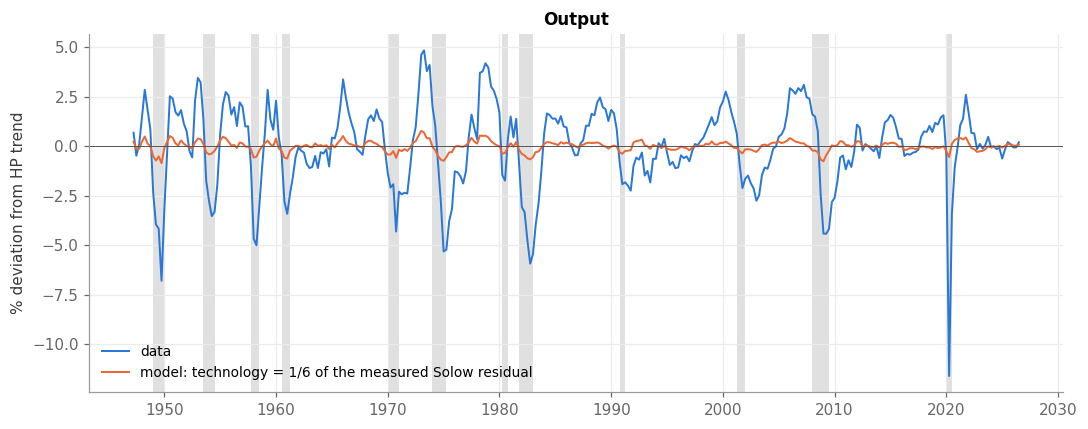

In [7]:
fig, ax = plt.subplots(figsize=(10, 4))
bcdata.shade_recessions(ax, levels["recession"])
ax.plot(cycles.index, cycles["GDP"], color=COLORS["gdp"], lw=1.3, label="data")
ax.plot(fed.index, fed["GDP"] / 6, color=COLORS["series"], lw=1.3,
        label="model: technology = 1/6 of the measured Solow residual")
ax.axhline(0, color="0.3", lw=0.6)
ax.set_ylabel("% deviation from HP trend")
ax.set_title("Output")
ax.legend(loc="lower left", fontsize=9)
plt.tight_layout()

The model output is far too smooth. The model has no **amplification mechanism** that turns small shocks into large fluctuations: its volatility is the volatility of the shocks we feed in.

#### Little internal propagation: a one-quarter shock

To understand why there is so little internal propagation, consider the response to a technology increase that lasts only one quarter: technology rises by 1% at $t = 0$ and returns to its steady state after one quarter, which households know (a transitory step shock as in Lecture 3, solved by `rbc.irf_step`).

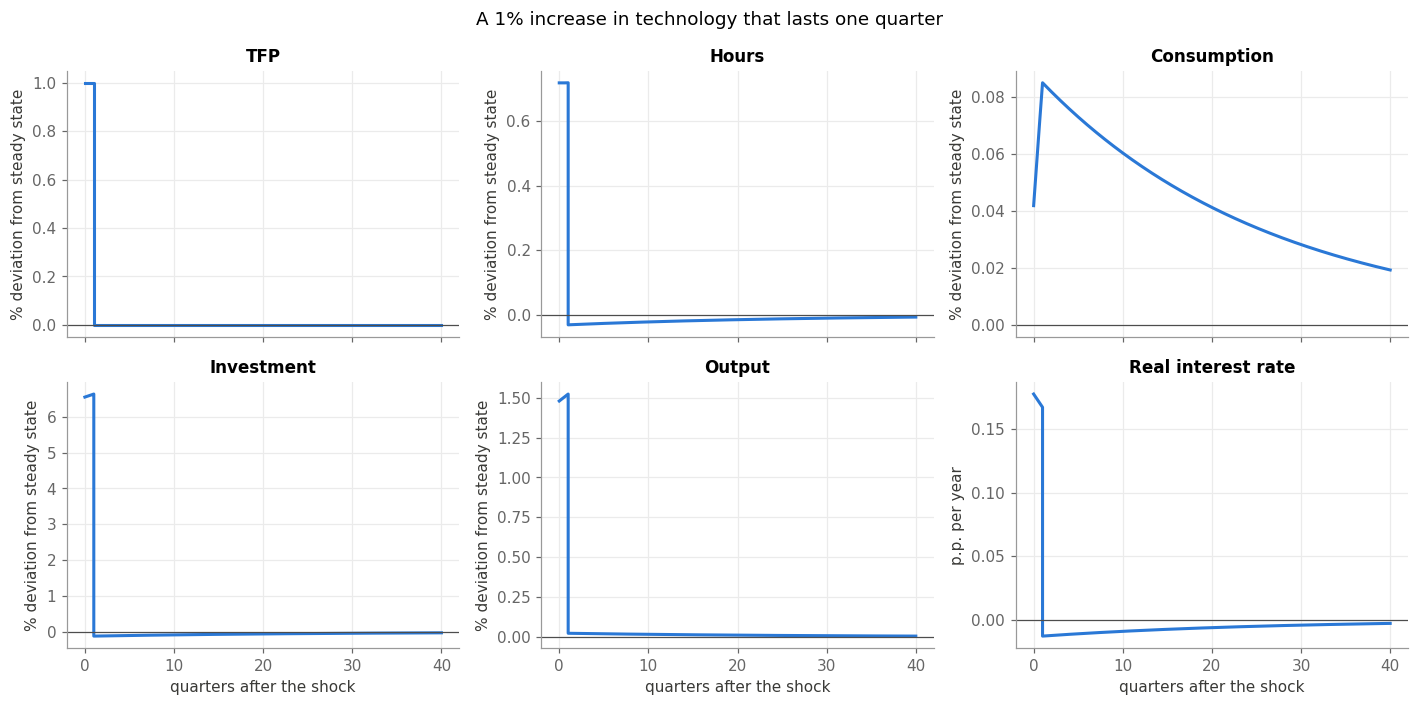

In [8]:
IRF_VARS = [("Z", "TFP"), ("L", "Hours"), ("C", "Consumption"),
            ("I", "Investment"), ("Y", "Output"), ("r (p.p.)", "Real interest rate")]


def irf_grid(df, title):
    fig, axes = plt.subplots(2, 3, figsize=(13, 6.5), sharex=True)
    for ax, (v, lab) in zip(axes.flat, IRF_VARS):
        ax.plot(4 * df.index, df[v], color=COLORS["gdp"], lw=2)
        ax.axhline(0, color="0.3", lw=0.8)
        ax.set_title(lab)
        ax.set_ylabel("p.p. per year" if v == "r (p.p.)" else "% deviation from steady state")
    for ax in axes[1]:
        ax.set_xlabel("quarters after the shock")
    fig.suptitle(title)
    plt.tight_layout()
    return axes


one_q = rbc.irf_step(p, z0=0.01, t1=0.25, T=10, n=401)
irf_grid(one_q, "A 1% increase in technology that lasts one quarter");

- **Hours and output.** With log utility, the income and substitution effects of a permanent change in productivity (nearly) offset each other (Lecture 2). With a temporary shock the household is barely richer, so the substitution effect dominates and labor supply rises: hours rise by about 0.7% and output by almost 1.5%, close to the $\frac{3}{2}$ of (AMP) without a wealth effect.
- **Consumption and investment.** The household could consume all the extra income now, but it wants to smooth consumption. Saving rises, so investment rises sharply today (more than 6%), while consumption barely moves.
- **After the first quarter.** Technology is back at its steady state, but capital is above it. The transitional dynamics of the growth model set in (Lecture 2): the household gradually runs down the excess capital with high consumption and low hours, and investment is below its steady state. The real interest rate falls below its steady state and gradually rises back.

The key point: in the model there is no reason why a quarter of high output and hours should be followed by more quarters of high output and hours. Output returns almost exactly to its steady state as soon as technology does. The model has essentially no **internal propagation**.

#### Propagation with a persistent shock

Now consider a highly persistent shock: the response to a 1% increase in technology that decays with quarterly persistence 0.95, our calibration (`rbc.irf`). The output panel also shows technology itself (dashed).

consumption peaks after 15 quarters; the real rate falls below its steady state after 15 quarters


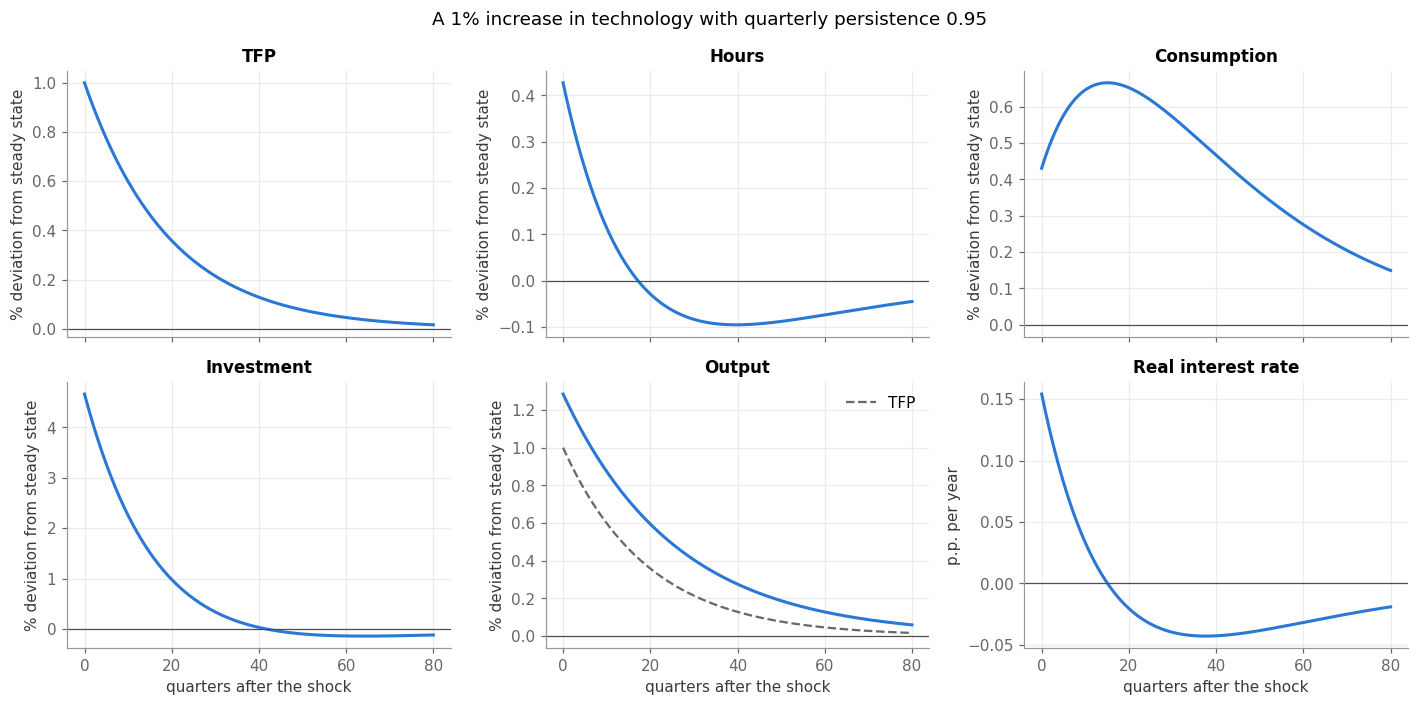

In [9]:
pers = rbc.irf(p, z0=0.01, theta_z=theta, T=20, n=401)
axes = irf_grid(pers, "A 1% increase in technology with quarterly persistence 0.95")
axes[1, 1].plot(4 * pers.index, pers["Z"], color=COLORS["trend"], lw=1.5, ls="--", label="TFP")
axes[1, 1].legend(loc="upper right")
print(f"consumption peaks after {4 * pers['C'].idxmax():.0f} quarters; "
      f"the real rate falls below its steady state after {4 * pers.index[(pers['r (p.p.)'] < 0).argmax()]:.0f} quarters")

The same mechanisms are now drawn out over time.

- **Hours.** Productivity is high for a long time, so workers increase their labor supply, but by less than after the one-quarter shock (0.4% vs. 0.7%), because the household is now richer and the wealth effect is stronger.
- **Real interest rate and consumption.** The marginal product of capital schedule is shifted up by the productivity shock and by the increase in hours, while capital responds only gradually through the accumulation of investment. So the real interest rate rises initially, then falls below its steady state and slowly reverts. By the Euler equation (EE), consumption grows while the real rate is above its steady state and falls afterwards: consumption is hump-shaped.
- **Output** is very persistent. The initial part of the response is determined by the productivity shock, which now lasts much longer, so hours and output are high for a while. The later part is determined by the transitional dynamics, as capital, which has been accumulated, is run down again.

But compare output with technology in the output panel: output follows technology closely. The persistence of output comes from the persistence of the shock, not from the model.

### 2.2 Rotemberg and Woodford (1996)

[Rotemberg and Woodford (1996)](https://ideas.repec.org/a/aea/aecrev/v86y1996i1p71-89.html) have a simple but powerful idea: in the data, shocks lead to large **predictable** movements and **co**movements in the series. In the basic RBC model, predictable movements are small. Furthermore, predictable comovements can even have the wrong sign.

To identify the shocks, they estimate a VAR in output growth $\Delta y_t$, the consumption–output ratio $c_t - y_t$, and hours $h_t$ (lowercase letters are logs):

$$
u_t = \begin{bmatrix}\Delta y_t \\ c_t - y_t \\ h_t\end{bmatrix}, \qquad u_t = A u_{t-1} + \varepsilon_t . \tag{VAR}
$$

All variables in this system are stationary. We want to know the predictable movements in the variables. To construct them, Rotemberg and Woodford use impulse response functions (IRFs), the path of a variable in response to a shock. In the VAR, the response of output growth at horizons $0, 1, 2, \dots, k$ is

$$
e_1\varepsilon_t,\quad e_1 A\varepsilon_t,\quad e_1 A^2\varepsilon_t,\quad \dots,\quad e_1 A^k\varepsilon_t ,
$$

where $e_1 = [1\ 0\ 0]$ is a selection vector. This is the response of the first difference of output. The cumulative response of output growth gives the response of the *level* of output (hats now denote predictable movements):

$$
\begin{aligned}
\Delta\hat y_t + \Delta\hat y_{t+1} + \dots + \Delta\hat y_{t+k}
&= (\hat y_t - \hat y_{t-1}) + (\hat y_{t+1} - \hat y_t) + \dots + (\hat y_{t+k} - \hat y_{t+k-1}) \\
&= \hat y_{t+k} - \hat y_{t-1} \\
&= e_1\left(I + A + A^2 + \dots + A^k\right)\varepsilon_t .
\end{aligned}
$$

The predictable change in output between $t$ and $t+k$ excludes the impact response:

$$
\begin{aligned}
\Delta\hat y^k_t &\equiv \hat y_{t+k} - \hat y_t \\
&= e_1\left(A + A^2 + \dots + A^k\right)\varepsilon_t \\
&\equiv B^k_y\,\varepsilon_t .
\end{aligned}
$$

Here $\Delta\hat y^k_t$ is a forecast of how output will move between $t$ and $t+k$: standing at time $t$, we expect output to change on average by $\Delta\hat y^k_t$ over the next $k$ periods. Letting $k \to \infty$ gives the response in the very long run,

$$
\Delta\hat y^\infty_t = \lim_{k\to\infty}\left(\hat y_{t+k} - \hat y_t\right) = e_1 (I - A)^{-1} A\,\varepsilon_t .
$$

With these predictable movements we can assess how much of the variation in output is predictable at horizon $k$. The predictable variation in output at horizon $k$ is

$$
\operatorname{cov}\left(\Delta\hat y^k_t, \Delta\hat y^k_t\right) = \operatorname{cov}\left(B^k_y\varepsilon_t, B^k_y\varepsilon_t\right) = B^k_y\,\Omega_\varepsilon\,(B^k_y)' ,
$$

where $\Omega_\varepsilon$ is the covariance matrix of $\varepsilon_t$. Likewise we can compute predictable **co**movements across variables. For example, the predictable covariance between output and consumption is

$$
\operatorname{cov}\left(\Delta\hat y^k_t, \Delta\hat c^k_t\right) = B^k_y\,\Omega_\varepsilon\,(B^k_c)' .
$$

We can then compare $\operatorname{cov}(\Delta\hat y^k_t, \Delta\hat y^k_t)$, the predictable movements, with $\operatorname{cov}(\Delta y^k_t, \Delta y^k_t)$, the total movements. With estimates of $A$ from the data and from the model, at horizon $k = 12$ quarters they find:

| | Data | Model |
|---|---|---|
| predictable: $\operatorname{cov}(\Delta\hat y^k_t, \Delta\hat y^k_t)$ | 0.0322 | 0.0023 |
| total: $\operatorname{cov}(\Delta y^k_t, \Delta y^k_t)$ | 0.0445 | 0.0212 |

Importantly, predictable movements are a large part of total output movements in the data. In the model, predictable movements are only a tiny fraction of the variation in output.

The following example helps to understand this result. Suppose $X_t$ follows an AR(1) process, $X_t = \rho X_{t-1} + \epsilon_t$ with $\epsilon_t \sim iid(0, \sigma_\epsilon^2)$. The variance of $X_t$ is $\sigma_\epsilon^2/(1-\rho^2)$. A given volatility of $X_t$ can be achieved by increasing $\sigma_\epsilon^2$ or by increasing $\rho$. These two approaches have sharply different implications for the predictability of $X_t$. In the extreme case $\rho = 0$, $X_t$ is not predictable at all. With $\rho$ close to one, predictability is high. The Rotemberg–Woodford result suggests that RBC models generate volatility through $\sigma_\epsilon^2$, while in the data volatility is high because of $\rho$.

To assess predictable comovements, we can regress one predictable movement on another. Regressing the predicted change in consumption at horizon $k$, $\Delta\hat c^k_t$, on the predicted change in output, $\Delta\hat y^k_t$, gives a coefficient of 0.2–0.5 in the data and 2.5 in the model. Regressing the predicted change in hours, $\Delta\hat h^k_t$, on $\Delta\hat y^k_t$ gives 1 in the data and −1 in the model.

There are two striking differences. First, in the model hours fall when output is expected to be high, while in the data high hours predict high output. Second, the response of consumption in the model is too large relative to the data (five to ten times larger). The model predicts that predictable consumption movements should be more variable than predictable output movements, whereas in practice they are not. The model makes this counterfactual prediction because the high interest rates that accompany a shortfall of capital from its steady state induce a substantial postponement of consumption. The model's high consumption coefficient implies that periods of high expected output growth should be periods in which the consumption–income ratio is low. In the data, a high $C/Y$ means that $Y$ is expected to grow. In the model, to anticipate high output in the future, I should consume less now, so $C/Y$ is low: I postpone consumption until the good times. Intertemporal substitution also explains why hours have a negative coefficient: I work hard now because the interest rate is high.

#### Predictable movements in our model

The most fundamental failing of the model can be explained simply. The model generates predictable movements only through departures of the current capital stock from its steady-state level. When capital is relatively low, its marginal product is relatively high, so the rate of return is high as well. With fairly strong intertemporal substitution, households then enjoy both less current consumption and less current leisure than in the steady state. So consumption is expected to rise while hours are expected to fall. More generally, consumption and hours are expected to move in opposite directions, so the regression coefficients of consumption on output and of hours on output have opposite signs. The figure shows this in our model, as in Rotemberg and Woodford's Figure 2: capital starts 1% below its steady state.

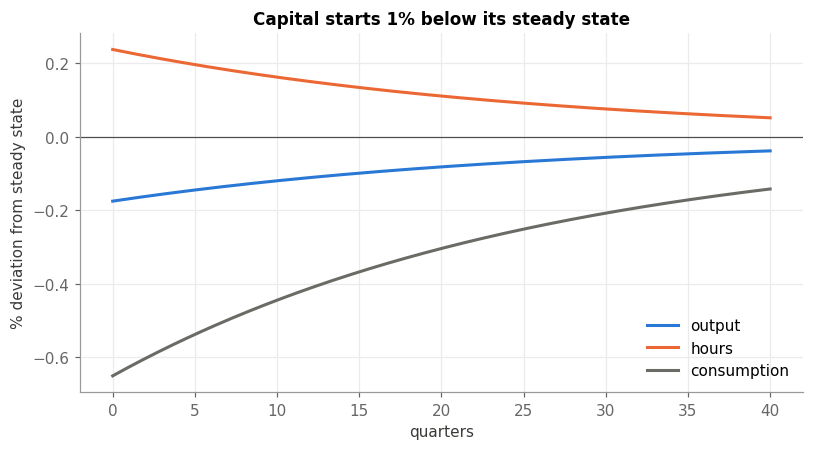

In [10]:
gap = rbc.irf(p, k0=-0.01, T=10, n=401)
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for var, col, lab in [("Y", COLORS["gdp"], "output"), ("L", COLORS["series"], "hours"),
                      ("C", COLORS["trend"], "consumption")]:
    ax.plot(4 * gap.index, gap[var], color=col, lw=2, label=lab)
ax.axhline(0, color="0.3", lw=0.8)
ax.set_xlabel("quarters")
ax.set_ylabel("% deviation from steady state")
ax.set_title("Capital starts 1% below its steady state")
ax.legend(loc="lower right")
plt.tight_layout()

Output and consumption are expected to rise, while hours are expected to fall.

We can also compute the predictable movements of Rotemberg and Woodford in our model. We want to know what the model predicts on its own, not what it inherits from a forecastable shock process. So, as in Rotemberg and Woodford, technology is a random walk: households expect technology to stay at its current level, and all predictable movements come from the model's internal dynamics. We repeat the exercise of Section 1 (feed in the measured Solow residual), but with the policy function (POL) for permanent changes in technology ($\theta = 0$).

Because the model is linear, the forecast of the future is the perfect-foresight path from the current state, with technology held at its current level (certainty equivalence). By (HIST) with $\hat z_t$ constant, the forecast of capital $h$ years ahead is

$$
\mathbb{E}_t\hat k_{t+h} = e^{\mu_s h}\hat k_t + \frac{e^{\mu_s h} - 1}{\mu_s}\,\nu_{kz}\hat z_t .
$$

Every other variable is a linear function of the state, $\hat v_t = a_v\hat k_t + b_v\hat z_t$ (output, consumption, hours, ...). Its predictable change over the next $h$ years is

$$
\begin{aligned}
\Delta\hat v^h_t &\equiv \mathbb{E}_t\hat v_{t+h} - \hat v_t \\
&= a_v\left(\mathbb{E}_t\hat k_{t+h} - \hat k_t\right) + b_v\left(\mathbb{E}_t\hat z_{t+h} - \hat z_t\right) \\
&= a_v\left(\mathbb{E}_t\hat k_{t+h} - \hat k_t\right) \\
&= a_v\left(e^{\mu_s h} - 1\right)\left(\hat k_t + \frac{\nu_{kz}}{\mu_s}\hat z_t\right) .
\end{aligned}
\tag{PRED}
$$

The last term in parentheses is the gap between capital and the steady state that corresponds to current technology, $-\nu_{kz}\hat z_t/\mu_s$. All predictable movements are proportional to this gap. The regression coefficients of predictable changes on each other are therefore ratios of the coefficients $a_v$, which are also the ratios of the impulse responses in the figure: for example, the consumption coefficient equals the change in consumption over the next $k$ quarters divided by the change in output. The total change is the actual change along the simulated path.

In [11]:
H = 12                                                 # horizon: 12 quarters
rw = rbc.policy_coefficients(p, 0.0)                   # (POL) with random-walk technology

# (HIST) with the measured Solow residual, as in Section 1
e_rw = np.exp(rw["mu_s"] * h)
k_rw = np.zeros(T)
for n in range(T - 1):
    k_rw[n + 1] = e_rw * k_rw[n] + rw["nu_kz"] * (e_rw - 1) / rw["mu_s"] * z[n]
lam_rw = rw["nu_lk"] * k_rw + rw["nu_lz"] * z
path = rbc.derived(p, levels.index, k_rw, lam_rw, z, np.zeros(T))[["Y", "C", "L"]]

# (PRED): a_v = loading on k, including the response of lambda to k
lo = rbc.loadings(p)[["Y", "C", "L"]]
a_v = lo.loc["k"] + rw["nu_lk"] * lo.loc["lam"]
gap_k = k_rw + rw["nu_kz"] / rw["mu_s"] * z
pred = pd.DataFrame(np.outer((np.exp(rw["mu_s"] * H / 4) - 1) * gap_k, a_v),
                    index=levels.index, columns=a_v.index).iloc[:-H]
total = (path.shift(-H) - path).iloc[:-H]


def coef(x, y):                                        # OLS slope of x on y
    return np.cov(x, y)[0, 1] / np.var(y, ddof=1)

d = gap.loc[H / 4] - gap.iloc[0]                       # changes over 12 quarters in the figure
pd.DataFrame({
    "Data (RW 1996)": ["0.72", "0.2 to 0.5", "1"],
    "Model (RW 1996)": ["0.11", "2.5", "-1"],
    "Our model": [f"{np.var(pred['Y']) / np.var(total['Y']):.3f}",
                  f"{coef(pred['C'], pred['Y']):.2f}  (figure: {d['C'] / d['Y']:.2f})",
                  f"{coef(pred['L'], pred['Y']):.2f}  (figure: {d['L'] / d['Y']:.2f})"],
}, index=["predictable / total variance of 12-quarter output change",
          "coefficient of predictable consumption change on output change",
          "coefficient of predictable hours change on output change"])

,Data (RW 1996),Model (RW 1996),Our model
predictable / total variance of 12-quarter output change,0.72,0.11,0.008
coefficient of predictable consumption change on output change,0.2 to 0.5,2.5,3.72 (figure: 3.72)
coefficient of predictable hours change on output change,1,-1,-1.36 (figure: -1.36)


The first row divides predictable by total variance (for Rotemberg and Woodford: $0.0322/0.0445$ and $0.0023/0.0212$). In our model, with random-walk technology, almost none of the variation in output over the next three years is predictable. Consumption is predicted to move several times as much as output, and hours to move in the opposite direction, while in the data consumption, hours and output are all predicted to move together.

Why does the model fail? Rotemberg and Woodford suggest that the model is not rich enough: it misses some margins (e.g., variable factor utilization), and we need more than one shock.

### 2.3 Are the parameters plausible?

There is a concern about the plausibility of the parameters the model needs. For RBC models to work, labor supply has to be elastic, and in particular the intratemporal elasticity of labor supply (the Frisch elasticity $\eta$) has to be high. The micro-level evidence suggests that these elasticities are fairly small. The figure repeats the exercise of Section 1, feeding the measured Solow residual into the model, for different values of $\eta$: from 0.5, in the range of micro estimates, to the limit $\eta \to \infty$ (indivisible labor, see below). All other parameters are unchanged.

eta =       0.5:  SD(hours) / SD(output) = 0.22,  corr(real wage, output) = 1.00
eta =         1:  SD(hours) / SD(output) = 0.34,  corr(real wage, output) = 0.99
eta =         4:  SD(hours) / SD(output) = 0.58,  corr(real wage, output) = 0.95
eta =     1e+06:  SD(hours) / SD(output) = 0.77,  corr(real wage, output) = 0.81
data:              SD(hours) / SD(output) = 0.97,  corr(real wage, output) = 0.02


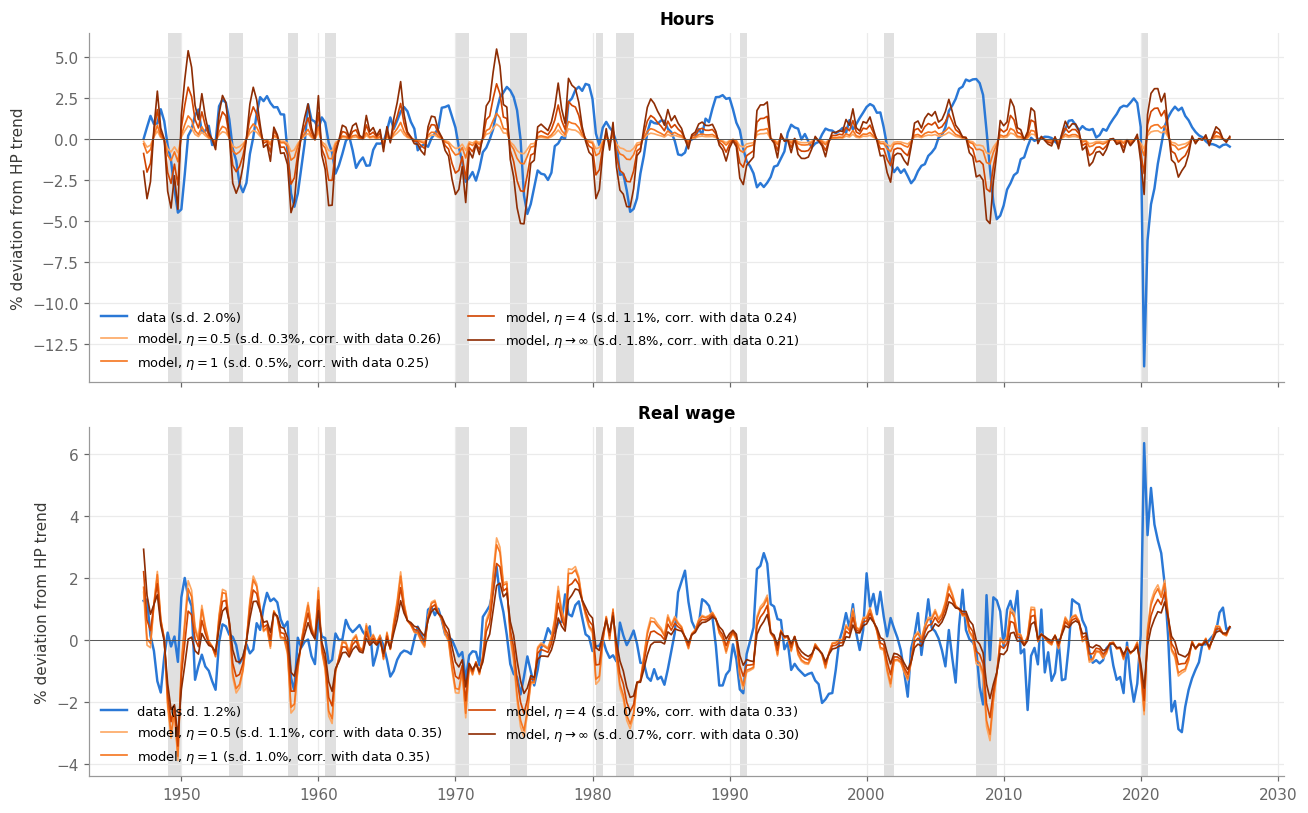

In [12]:
def history(p):
    # Section 1: feed the measured Solow residual into the model with parameters p; HP cycles in %
    pc_ = rbc.policy_coefficients(p, theta)
    e_ = np.exp(pc_["mu_s"] * h)
    k_ = np.zeros(T)
    for n in range(T - 1):
        k_[n + 1] = e_ * k_[n] + pc_["nu_kz"] * (e_ - 1) / pc_["mu_s"] * z[n]      # (HIST)
    lam_ = pc_["nu_lk"] * k_ + pc_["nu_lz"] * z                                     # (POL)
    x_ = rbc.derived(p, levels.index, k_, lam_, z, np.zeros(T)).rename(columns=NAMES)[list(NAMES.values())]
    return pd.DataFrame(HPC @ x_.values, index=levels.index, columns=x_.columns)


ETAS = [0.5, 1.0, 4.0, 1e6]                             # Frisch elasticity; 1e6 ~ infinite: indivisible labor (Hansen, 1985)
hist_eta = {eta: history(rbc.Params(sg=0.2, eta=eta)) for eta in ETAS}
shades = plt.cm.Oranges(np.linspace(0.4, 0.95, len(ETAS)))

fig, axes = plt.subplots(2, 1, figsize=(12, 7.5), sharex=True)
for ax, var, title in [(axes[0], "Hours", "Hours"), (axes[1], "Real Wage", "Real wage")]:
    bcdata.shade_recessions(ax, levels["recession"])
    ax.plot(cycles.index, cycles[var], color=COLORS["gdp"], lw=1.6,
            label=f"data (s.d. {cycles[var].std():.1f}%)")
    for eta, col in zip(ETAS, shades):
        s_ = hist_eta[eta][var]
        lab = "$\\eta \\to \\infty$" if eta > 1e5 else f"$\\eta = {eta:g}$"
        ax.plot(s_.index, s_, color=col, lw=1.1,
                label=f"model, {lab} (s.d. {s_.std():.1f}%, corr. with data {s_.corr(cycles[var]):.2f})")
    ax.axhline(0, color="0.3", lw=0.6)
    ax.set_ylabel("% deviation from HP trend")
    ax.set_title(title)
    ax.legend(loc="lower left", fontsize=8.5, ncol=2)
plt.tight_layout()

for eta in ETAS:
    m_ = hist_eta[eta]
    print(f"eta = {eta:>9g}:  SD(hours) / SD(output) = {m_['Hours'].std() / m_['GDP'].std():.2f},  "
          f"corr(real wage, output) = {m_['Real Wage'].corr(m_['GDP']):.2f}")
print(f"data:              SD(hours) / SD(output) = {data.loc['Hours', 'SD / SD(GDP)']:.2f},  "
      f"corr(real wage, output) = {data.loc['Real Wage', 'Corr(x, GDP)']:.2f}")

A higher Frisch elasticity makes hours more volatile. But even an elasticity of 4, far above the micro estimates, generates only about half the volatility of hours in the data. Only in the limit $\eta \to \infty$ are hours about as volatile as in the data. Even then, hours in the model do not track hours in the data (the correlation stays between 0.2 and 0.25), and the real wage remains far too procyclical. The real wage barely depends on $\eta$: it equals the marginal product of labor, which moves with technology.

When we work with an aggregate model, the aggregate elasticity combines two things: (i) micro-level elasticities and (ii) aggregation. Aggregation can be very important. A striking example is due to [Houthakker (1955)](https://doi.org/10.2307/2296148): if every firm has a Leontief production function and the distribution of firms is Pareto, then the aggregate production function is Cobb–Douglas. Similarly, the distinction between the intensive and extensive margins of labor adjustment (Lecture 1) could be very important for the aggregate labor supply elasticity:

- [Hansen (1985)](https://doi.org/10.1016/0304-3932%2885%2990039-X) assumes that labor is indivisible: individuals either work a fixed number of hours or not at all, and employment is allocated by lotteries. Then the economy behaves as if the representative household had an infinite Frisch elasticity, whatever the preferences of individuals (the $\eta \to \infty$ line in the figure).
- [Rogerson and Wallenius (2009)](https://doi.org/10.1016/j.jet.2008.05.011) study a life-cycle model in which much of the adjustment of hours happens at the extensive margin (when to enter and leave work). Small micro elasticities at the intensive margin are then consistent with large macro elasticities: micro estimates are not informative about the macro elasticity.
- [Chetty, Guren, Manoli, and Weber (2013)](https://doi.org/10.1086/669170) collect the micro evidence on extensive-margin elasticities. They find modest elasticities at the extensive margin too, and conclude that the micro evidence points to an aggregate Frisch elasticity of hours well below the values that macro models typically need.

### 2.4 The Solow residual as a technology shock

**What is a "decline" in technology?** How is it possible to have technological regress? We measure technology with the Solow residual,

$$
\hat z_t = \hat y_t - (1-\alpha)\,\hat l_t - \alpha\,\hat k_t ,
$$

where $\alpha$ is estimated from the labor share, $1-\alpha = \frac{WL}{Y}$. Measured TFP fell a lot during the Great Depression in the U.S. But technological regress is unlikely to have caused the Depression. At least, we are not aware of any technological problem that led to the Great Depression. [Lucas (1994)](https://doi.org/10.1016/0304-3932%2894%2990055-8) writes (p. 13), after showing the Solow residuals for 1928–33:

> [I]magine trying to rewrite the Great Contraction chapter of *A Monetary History* with shocks of this kind playing the role Friedman and Schwartz assign to monetary contractions. What technological or psychological events could have induced such behavior in a large, diversified economy? How could such events have gone unremarked at the time, and remain invisible even to hindsight?

More generally, we cannot identify large movements in measured technology with particular events and discoveries. In Lecture 1 the Solow residual fell in almost every postwar recession.

**Is the Solow residual exogenous?** Another problem with using the Solow residual as a structural shock in RBC models is that $Z_t$ does not seem "exogenous." To identify the effects of a shock, we want it to be uncorrelated with other shocks. Otherwise, when we look at the response of the economy to a shock, we do not know whether we see the effect of a particular force ("technology") or the effect of something that is correlated with technology. We therefore usually require, for example, $\rho(Z, G) = 0$. There is no particular reason to believe that government spending raises the level of technology, at least in the short run. However, the Solow residual in the data is correlated with non-technology shocks:

- [Hall (1988)](https://doi.org/10.1086/261570): $\rho(Z, \text{demand shifters}) \neq 0$,
- [Evans (1992)](https://doi.org/10.1016/0304-3932%2892%2990012-Q): $\rho(Z, \text{monetary policy shocks}) \neq 0$.

This is a problem: if measured technology shocks are endogenous, the model can fit well even though technology has no causal effect on fluctuations. We could not conclude that technology drives business cycles.

#### Galí (1999): technology and non-technology shocks

[Galí (1999)](https://doi.org/10.1257/aer.89.1.249) argues that matching the variances and covariances of the time series is a weak test of the model. These are only unconditional moments, and when there are several shocks we can probably fit the variances and covariances of consumption, hours, output, etc. by choosing the right mix of shocks. The model makes sharper predictions about the **impulse responses to particular shocks**, which are conditional moments: is the response to a technology shock in particular correct?

To answer this, Galí estimates a structural VAR in labor productivity and hours that separates technology from non-technology shocks. The identifying assumption, in the spirit of [Blanchard and Quah (1989)](https://www.jstor.org/stable/1827924), is that only technology shocks have a permanent effect on labor productivity; other shocks may affect productivity only temporarily. He finds that after a positive technology shock productivity and output rise, but **hours fall**. In the RBC model hours rise after a technology improvement (Section 2.1). Compare also Section 1.1, where we used the HP-filtered Solow residual as the shock and found that hours rise. Galí concludes that the Solow residual mixes technology with other shocks.

#### Variable utilization

One of the biggest hurdles in inferring technology shocks from the Solow residual is **variable utilization**. Proxies for capital utilization and for labor hoarding (the effort of workers) are highly procyclical. The Solow residual picks up this variation in utilization in addition to "true" technology. When technology is measured correctly, it is much less volatile. The model fed with one sixth of the Solow residual in Section 2.1 represents this case: the basic model then generates far too little volatility.

[King and Rebelo (1999)](https://doi.org/10.1016/S1574-0048%2899%2910022-3) take this criticism seriously. They add indivisible labor (Section 2.3) and variable capital utilization to the RBC model, and feed in a Solow residual that is adjusted for variable utilization. The model then does very well, even though the adjusted technology shocks are much smaller. The reason is much more amplification, because the labor supply and labor demand schedules are more elastic. Labor supply is elastic because labor is indivisible. Labor demand is elastic because of variable utilization, which also makes output more volatile.

[Basu, Fernald, and Kimball (2006)](https://doi.org/10.1257/aer.96.5.1418) construct a more econometrically sophisticated measure of technology. They "purify" the Solow residual by controlling for the varying utilization of capital and labor, non-constant returns to scale, imperfect competition, and aggregation effects. Their measure of technology varies about half as much as TFP, and its changes are permanent and serially uncorrelated. What happens when technology improves? In the short run, technology improvements are **contractionary**: hours and investment fall, as in Galí (1999). This is totally inconsistent with the RBC model. The long-run effects, however, are consistent with the RBC model and the neoclassical growth model. Models with sticky prices (New Keynesian models) can explain this short-run response.

## 3. Business cycle accounting

Where do we go from here? We could add various frictions to the model: in price setting, in the labor market, in financial markets. But which ones? [Chari, Kehoe, and McGrattan (2007)](https://doi.org/10.1111/j.1468-0262.2007.00768.x) propose to let the data guide us. The idea is to add time-varying implicit taxes on consumption, labor, and investment to the RBC model, choose them so that the model matches the data, and see which of these implicit taxes, or **wedges**, matter. Chari, Kehoe, and McGrattan show how different frictions map into different wedges. For example, financial frictions show up as an investment wedge.

**Labor and investment wedges.** Suppose workers pay a time-varying tax $\tau^L_t$ on labor income. With $C_t = 1/\lambda_t$ (HH-FOC), the first-order conditions of the worker and the firm are

$$
(1-\tau^L_t)\,W_t = C_t L_t^{1/\eta} \qquad\text{and}\qquad W_t = (1-\alpha)\frac{Y_t}{L_t} .
$$

The right-hand side of the first condition is the marginal rate of substitution between leisure and consumption, $MRS_t$. The right-hand side of the second is the marginal product of labor, $MPL_t$. Combining the two, the implicit tax is the **labor wedge**:

$$
1-\tau^L_t = \frac{C_t L_t^{1/\eta}}{(1-\alpha)Y_t/L_t} = \frac{MRS_t}{MPL_t} . \tag{LW}
$$

With data on $Y_t$, $L_t$, and $C_t$, and values for $\eta$ and $\alpha$, we can compute the labor wedge in the data. We usually work in log deviations from trend, so the constant $1-\alpha$ drops out. Similarly, a time-varying tax $\tau^K_t$ on the return to capital changes the Euler equation (EE) to

$$
\frac{\dot C_t}{C_t} = (1-\tau^K_t)\,\alpha\frac{Y_t}{K_t} - \delta - \rho , \tag{IW}
$$

which defines the **investment wedge** $1-\tau^K_t$. In our RBC model with technology shocks both wedges are zero by construction: any movement in the measured wedges is something the model cannot account for.

### 3.1 The labor wedge

The key finding in the literature is that the labor wedge is quantitatively large and highly countercyclical ([Chari, Kehoe, and McGrattan, 2007](https://doi.org/10.1111/j.1468-0262.2007.00768.x) and [Shimer, 2009](https://doi.org/10.1257/mac.1.1.280)). The figure below illustrates Shimer's result that the labor wedge rises in all recessions and declines in expansions.

**Deconstructing the labor wedge.** Does the labor wedge imply that the relevant frictions are in the labor market? Not exactly. The labor wedge combines labor and product market distortions. Write the labor market distortion as a gross wage markup, and the product market distortion as a gross price markup over marginal cost $MC_t$ (with $W_t$ the real wage and the price of output normalized to one):

$$
\begin{aligned}
1+\mu^W_t &= \frac{W_t}{MRS_t} , \\
1+\mu^P_t &= \frac{1}{MC_t} = \frac{1}{W_t/MPL_t} = \frac{MPL_t}{W_t} .
\end{aligned}
$$

Then the labor wedge can be written as a markup,

$$
1+\mu^L_t = \frac{1}{1-\tau^L_t} = \frac{MPL_t}{MRS_t} = \left(1+\mu^P_t\right)\left(1+\mu^W_t\right) . \tag{MARKUP}
$$

For $\tau^L_t$ and $\mu^L_t$ to be countercyclical, either gross price markups or gross wage markups (or both) must be countercyclical. But which one matters? We can construct $1+\mu^P_t$ and $1+\mu^W_t$ with the same data as the labor wedge plus the real wage. The figure does this with the data of Lecture 1 and $\eta = 1$.

,SD (%),"Corr(x, GDP)",share of Var(labor wedge)
labor wedge,3.23,-0.68,1.0
wage markup,3.39,-0.74,1.0
price markup,1.03,0.31,0.0


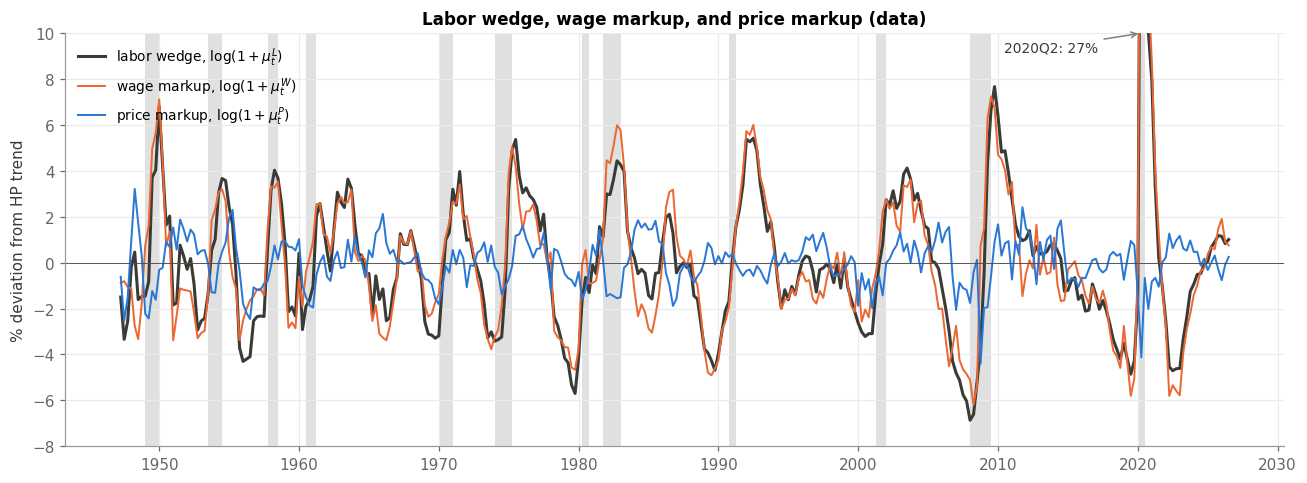

In [13]:
# labor wedge and its decomposition (MARKUP) in the data, in % deviations from HP trend
mrs = cycles["Consumption"] + cycles["Hours"] / p.eta          # log MRS = log C + (1/eta) log L
mpl = cycles["GDP"] - cycles["Hours"]                          # log MPL = log((1-alpha) Y / L) + const.
wedges = pd.DataFrame({"labor wedge": mpl - mrs,                              # log(1 + mu^L)
                       "wage markup": cycles["Real Wage"] - mrs,              # log(1 + mu^W)
                       "price markup": mpl - cycles["Real Wage"]})            # log(1 + mu^P)
labels = {"labor wedge": "labor wedge, $\\log(1+\\mu^L_t)$", "wage markup": "wage markup, $\\log(1+\\mu^W_t)$",
          "price markup": "price markup, $\\log(1+\\mu^P_t)$"}

fig, ax = plt.subplots(figsize=(12, 4.5))
bcdata.shade_recessions(ax, levels["recession"])
for (name, s_), col, lw in zip(wedges.items(), [COLORS["text"], COLORS["series"], COLORS["gdp"]], [2, 1.3, 1.3]):
    ax.plot(s_.index, s_, color=col, lw=lw, label=labels[name])
ax.axhline(0, color="0.3", lw=0.6)
ax.set_ylim(-8, 10)                                            # 2020Q2 is far off the scale
top = wedges["labor wedge"].idxmax()
ax.annotate(f"{top:%Y}Q{top.quarter}: {wedges['labor wedge'].max():.0f}%", xy=(top, 10), xytext=(-90, -12),
            textcoords="offset points", fontsize=9, color=COLORS["text"], arrowprops=dict(arrowstyle="->", color="0.5"))
ax.set_ylabel("% deviation from HP trend")
ax.set_title("Labor wedge, wage markup, and price markup (data)")
ax.legend(loc="upper left", fontsize=9)
plt.tight_layout()

pd.DataFrame({"SD (%)": wedges.std(),
              "Corr(x, GDP)": wedges.corrwith(cycles["GDP"]),
              "share of Var(labor wedge)": wedges.apply(lambda s_: s_.cov(wedges["labor wedge"])) / wedges["labor wedge"].var()}).round(2)

The labor wedge $\log(1+\mu^L_t)$ is strongly countercyclical. The last column splits its variance into the covariances of the two markups with the labor wedge (they add up to one). The wage markup explains almost all of the variation in the labor wedge, while the price markup, measured with the average wage, is if anything procyclical. This is the standard finding and motivated the literature on search and unemployment in the labor market.

[Bils, Klenow, and Malin (2018)](https://doi.org/10.1257/aer.20151260) argue that this conclusion has measurement issues: the average wage $W_t$ is a smoothed measure of the true marginal cost of labor. Using alternative measures of the marginal cost of labor, they find that the labor market wedge and the product market wedge are about equally important.

## Summary

- Fed with the measured Solow residual, the calibrated RBC model tracks HP-filtered output, consumption, and investment closely, but it fails in the labor market.
- There is little endogenous amplification or propagation in the RBC model. Dynamics and magnitude largely reflect the exogenous shocks.
- In the RBC model, almost none of the endogenous movements in output are predictable, and consumption and hours are predicted to move in opposite directions, unlike in the data ([Rotemberg and Woodford, 1996](https://ideas.repec.org/a/aea/aecrev/v86y1996i1p71-89.html)).
- Matching the volatility of hours requires a very elastic labor supply.
- The Solow residual is a problematic measure of technology.
- The labor wedge between the marginal rate of substitution and the marginal product of labor is strongly countercyclical.

## 4. Try it yourself

1. **How impressive is the fit of output?** The Solow residual in the data is $\hat z_t = \hat y_t - \alpha\hat k_t - (1-\alpha)\hat l_t$, and in the model $\hat y_t = \hat z_t + \alpha\hat k_t + (1-\alpha)\hat l_t$. Show that when we feed the measured Solow residual into the model, the gap between output in the data and in the model is $(1-\alpha)$ times the gap in hours plus $\alpha$ times the gap in capital. Use this to explain why the fit of output in Section 1 is much better than the fit of hours. What does it imply about the case for technology shocks as the driver of business cycles?
2. **Temporary vs. persistent shocks.** In Section 2.1 a technology increase that lasts one quarter raises hours by about 0.7%, while a shock with quarterly persistence 0.95 raises them by only about 0.4%. Explain the difference using the income and substitution effects of higher wages. Why does it create a tension for the RBC model to match the data?
3. **Good news is bad news for hours?** Rotemberg and Woodford find that hours are predicted to fall when output is predicted to rise. Use the labor market diagram of Lecture 3 to explain why this is true in the model whenever capital is below its steady state. What would have to be true about labor demand or labor supply for hours and output to be predicted to move together?
4. **Why doesn't $\eta$ move the wage?** In Section 2.3 a higher Frisch elasticity makes hours much more volatile, but the real wage remains almost perfectly procyclical. Explain this finding using the labor market diagram of Lecture 3. What would you need to get large movements in hours together with an acyclical real wage?
5. **Utilization and the Solow residual.** Suppose output is $Y_t = Z_t (u_t K_t)^{\alpha} L_t^{1-\alpha}$, where $u_t$ is the utilization of capital, but we compute the Solow residual with $K_t$ alone. Show that the measured Solow residual is $\hat z_t + \alpha\hat u_t$. If utilization rises in booms, in which direction does this bias measured technology over the cycle? Use your answer to explain why hours rise after an increase in the HP-filtered Solow residual in Section 1.1, while they fall after the identified technology shocks of Galí (1999) and Basu, Fernald, and Kimball (2006).
6. **Reading the labor wedge.** Suppose a recession is caused by a fall in demand. (a) If the real wage is rigid and firms stay on their labor demand curve, $W_t = MPL_t$, which of the two markups in (MARKUP) moves, and in which direction? (b) If instead prices are sticky and workers stay on their labor supply curve, $W_t = MRS_t$, which markup moves? Which frictions could generate the countercyclical labor wedge we measured in Section 3.1? Why might the average wage understate the movements in the true marginal cost of labor, as Bils, Klenow, and Malin (2018) argue?